# Diabetes Risk Screening Tool
**NextGen Institute · Machine Learning · Final Project (Idea #11)**

## 1 · Problem framing
- **Who has the problem?** Public-health programs and clinics: many people have diabetes or prediabetes and do not know it.
- **Decision the model supports:** tell a person, from a short questionnaire, whether they should see a doctor for a blood test. It is a *screening aid, not a diagnosis*.
- **Target:** `Diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes).
- **Metric that matters:** **Recall** on the positive class (a missed case is worse than an unnecessary check-up), while watching **precision** so we don't flood clinics. We also report ROC-AUC and PR-AUC because the classes are imbalanced. Accuracy is *not* used: a model that always says "no diabetes" already gets ~86% accuracy.
- **Design constraint:** the final app must be a *short* questionnaire (5-7 questions), so we also find the smallest set of questions that keeps most of the performance.

**Dataset:** CDC Diabetes Health Indicators (BRFSS 2015) — UCI: https://archive.ics.uci.edu/dataset/891 (also on Kaggle as *Diabetes Health Indicators Dataset*). Use the file `diabetes_binary_health_indicators_BRFSS2015.csv` and put it next to this notebook.

In [22]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
CV_FOLDS = 5
TARGET_RECALL = 0.80      # screening goal: catch at least 80% of people with (pre)diabetes
K_FINAL = 7               # questions in the final short questionnaire
sns.set_theme(style="whitegrid")

## 2 · Data understanding
Source: CDC BRFSS 2015 telephone health survey. Each row is one respondent; all columns are numeric codes.

| Column | Meaning |
|---|---|
| Diabetes_binary | **Target** — 0 no diabetes, 1 prediabetes/diabetes |
| HighBP, HighChol, CholCheck | told high blood pressure / high cholesterol; cholesterol checked in last 5 yrs (0/1) |
| BMI | body-mass index |
| Smoker, Stroke, HeartDiseaseorAttack | smoked 100+ cigarettes ever; history of stroke; coronary disease / heart attack |
| PhysActivity, Fruits, Veggies | physical activity last 30 days; eats fruit / vegetables daily |
| HvyAlcoholConsump | heavy drinker |
| AnyHealthcare, NoDocbcCost | has health coverage; skipped a doctor visit because of cost |
| GenHlth | self-rated general health, 1 (excellent) – 5 (poor) |
| MentHlth, PhysHlth | days of poor mental / physical health in last 30 days |
| DiffWalk | difficulty walking or climbing stairs |
| Sex | 0 female, 1 male |
| Age | 13 age groups: 1 = 18-24 ... 13 = 80+ |
| Education | 1-6 (higher = more education) |
| Income | 1-8 (higher = higher income) |

In [6]:
DATA_PATH = "archive\diabetes_binary_health_indicators_BRFSS2015.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.info()
df.head()

Shape: (253680, 22)
Missing values: 0
Duplicate rows: 24206
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  Gen

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [7]:
balance = df["Diabetes_binary"].value_counts(normalize=True).rename("share")
print(balance)
print(f"Accuracy of a 'nobody has diabetes' model: {balance.max():.1%}  <- why accuracy is a bad metric here")
df.describe().T

Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: share, dtype: float64
Accuracy of a 'nobody has diabetes' model: 86.1%  <- why accuracy is a bad metric here


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


## 3 · EDA
Univariate → bivariate → multivariate.

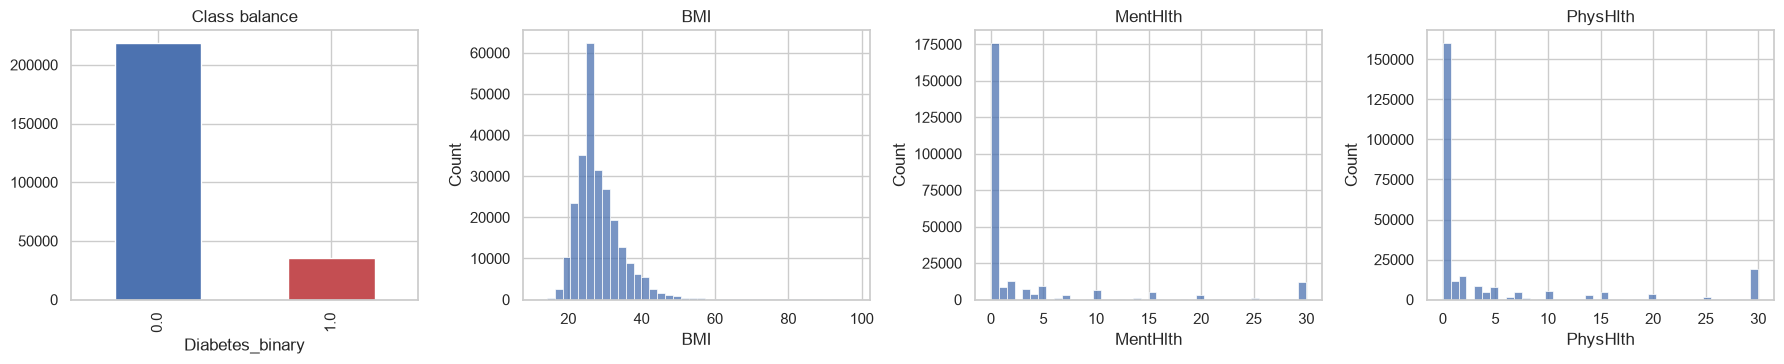

In [8]:
# Univariate: target balance + the 3 non-binary numeric columns
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
df["Diabetes_binary"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class balance")
for ax, c in zip(axes[1:], ["BMI", "MentHlth", "PhysHlth"]):
    sns.histplot(df[c], bins=40, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

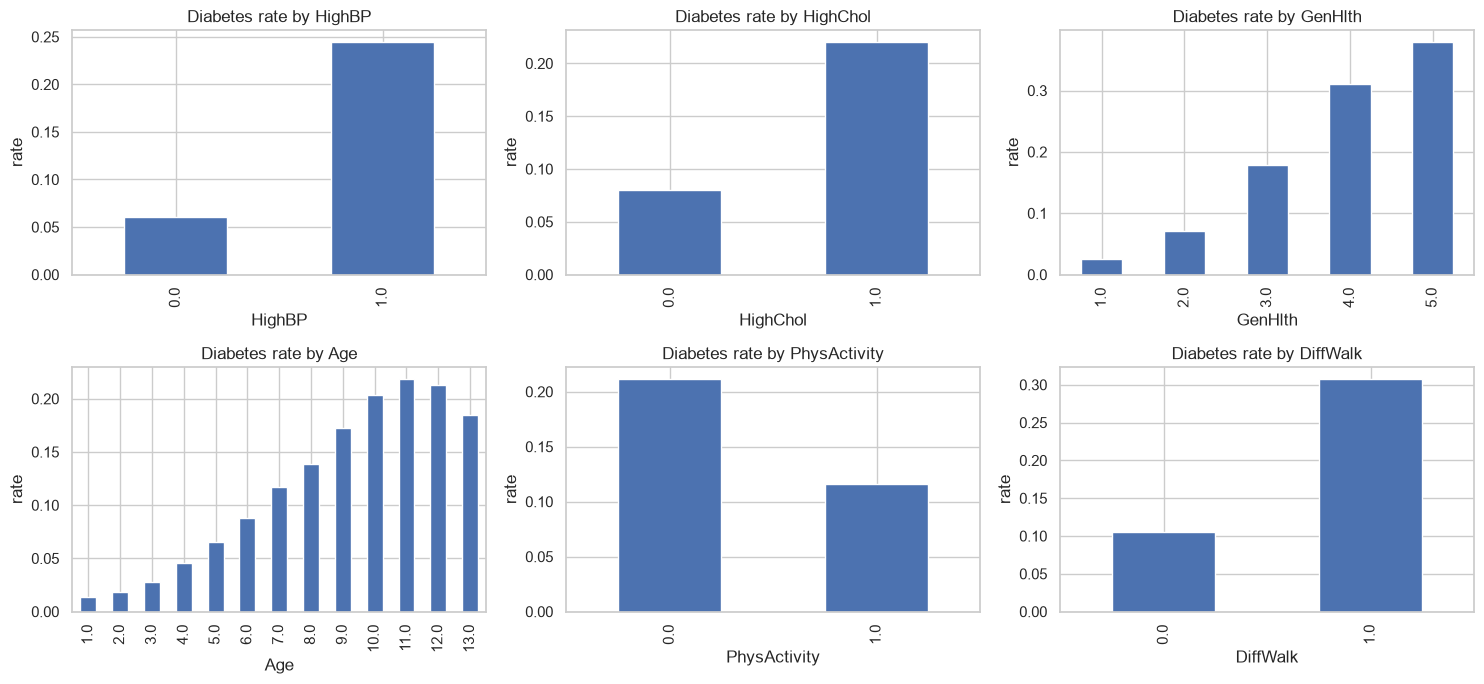

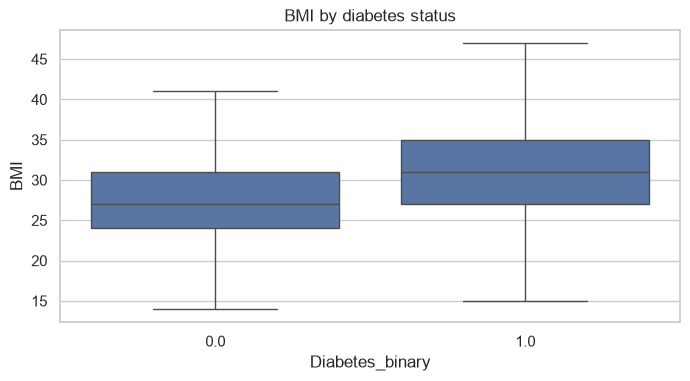

In [9]:
# Bivariate: diabetes rate by key features
rate_cols = ["HighBP", "HighChol", "GenHlth", "Age", "PhysActivity", "DiffWalk"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), rate_cols):
    df.groupby(c)["Diabetes_binary"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Diabetes rate by {c}"); ax.set_ylabel("rate")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 3.8))
sns.boxplot(data=df, x="Diabetes_binary", y="BMI", showfliers=False)
plt.title("BMI by diabetes status"); plt.show()

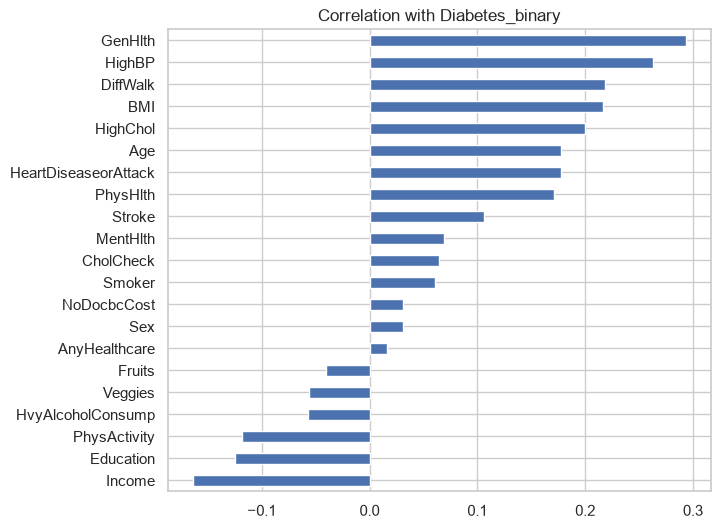

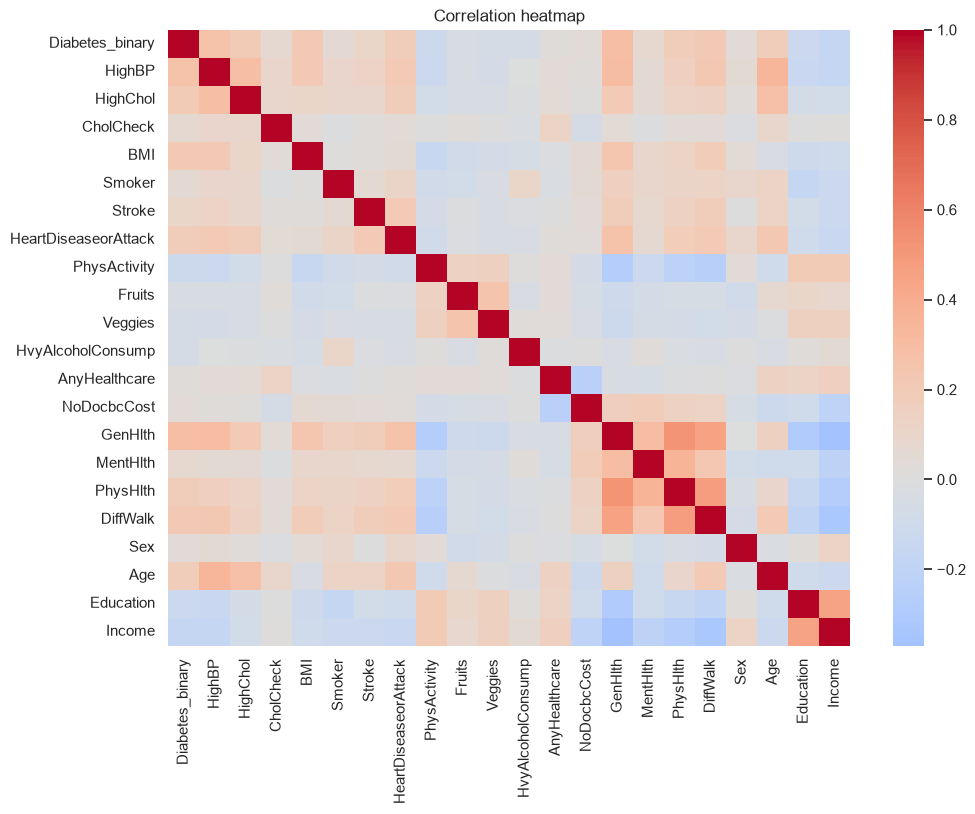

In [10]:
# Multivariate: correlation with the target + full heatmap
corr_t = df.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()
corr_t.plot(kind="barh", figsize=(7, 6), title="Correlation with Diabetes_binary"); plt.show()

plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap"); plt.show()

### EDA insights (edit these so they match **your** charts and numbers)
1. The classes are strongly imbalanced (~14% positive) → accuracy is misleading; use recall / PR-AUC and tune the decision threshold.
2. High blood pressure, high cholesterol, poor general health (`GenHlth`), difficulty walking and older age show a much higher diabetes rate in the bar charts.
3. BMI is higher on average for the positive class, but the distributions overlap a lot → no single feature separates the classes.
4. Physical activity and higher income/education are associated with a lower rate → possible socio-economic signal.
5. Many features are correlated (e.g. `GenHlth`, `PhysHlth`, `DiffWalk`) → a short questionnaire should be possible without losing much.

## 4 · Preprocessing
- No missing values in this file; all columns are already numeric codes, so we only **scale** the three continuous-like columns (needed for logistic regression) and pass the 0/1 and ordinal columns through. Ordinal codes (`Age`, `GenHlth`, `Education`, `Income`) keep their natural order, so no one-hot encoding is needed.
- BMI "outliers" are real survey values; we keep them (tree models are robust to them).
- We **drop duplicate rows first** (the survey file has many identical rows) so the same person can't be in both train and test.
- We **split before fitting anything** and everything else lives inside a scikit-learn `Pipeline` (no leakage).

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="Diabetes_binary")
y = df["Diabetes_binary"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape, " Positive rate:", round(y_train.mean(), 3))

NUMERIC = ["BMI", "MentHlth", "PhysHlth"]
ALL_FEATURES = list(X_train.columns)

def make_pipeline(model, features):
    num = [c for c in NUMERIC if c in features]
    prep = ColumnTransformer([("num", StandardScaler(), num)], remainder="passthrough")
    return Pipeline([("prep", prep), ("model", model)])

Train: (183579, 21)  Test: (45895, 21)  Positive rate: 0.153


## 5 · Modeling
A majority-class baseline plus three algorithms from the course, compared with stratified cross-validation **on the training set only**.

In [12]:
HGB_BASE = dict(max_iter=300, early_stopping=True, random_state=RANDOM_STATE)
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(**HGB_BASE),
}
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, m in models.items():
    res = cross_validate(make_pipeline(m, ALL_FEATURES), X_train, y_train, cv=cv,
                         scoring=["roc_auc", "average_precision"])
    rows.append({"model": name,
                 "CV ROC-AUC": res["test_roc_auc"].mean(),
                 "CV PR-AUC": res["test_average_precision"].mean()})
cv_table = pd.DataFrame(rows).set_index("model").round(4)
cv_table

,CV ROC-AUC,CV PR-AUC
model,,
Baseline (majority class),0.5000,0.1529
Logistic Regression,0.8062,0.4056
Random Forest,0.8121,0.4302
Hist Gradient Boosting,0.8147,0.4320


## 6 · Tuning & validation
Randomized search with cross-validation on the training data only, for the best family of models (gradient boosting in most runs — if another model wins in your table above, tune that one instead).

In [13]:
param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [3, 5, 7, None],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100, 200],
    "model__l2_regularization": [0, 0.1, 1, 10],
}
search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingClassifier(**HGB_BASE), ALL_FEATURES),
    param_dist, n_iter=15, scoring="roc_auc", cv=3, n_jobs=-1,
    random_state=RANDOM_STATE, verbose=1)
search.fit(X_train, y_train)

best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best params:", best_params)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
full_model = search.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_depth': 5, 'learning_rate': 0.03, 'l2_regularization': 0.1}
Best CV ROC-AUC: 0.8149


### Choosing the decision threshold (screening = recall first)
The default threshold of 0.5 misses most positives on imbalanced data. We pick the threshold using **out-of-fold predictions on the training set** so that recall reaches `TARGET_RECALL`, with the best precision possible at that recall. The test set is never touched for this choice.

In [14]:
def pick_threshold(model, X_, y_, target_recall=TARGET_RECALL):
    proba = cross_val_predict(clone(model), X_, y_,
                              cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                              method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_, proba)
    ok = np.where(rec[:-1] >= target_recall)[0]
    return float(thr[ok[-1]])          # highest threshold that still reaches the target recall

thr_full = pick_threshold(full_model, X_train, y_train)
print(f"Chosen threshold (full model): {thr_full:.3f}")

Chosen threshold (full model): 0.143


## 7 · Evaluation on the untouched test set

In [15]:
def evaluate(model, X_, y_, thr):
    p = model.predict_proba(X_)[:, 1]
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_, p), "PR-AUC": average_precision_score(y_, p),
            "Recall": recall_score(y_, pred), "Precision": precision_score(y_, pred),
            "F1": f1_score(y_, pred)}, p, pred

m05, _, _ = evaluate(full_model, X_test, y_test, 0.5)
mthr, p_test, pred_test = evaluate(full_model, X_test, y_test, thr_full)
base_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
baseline = {"ROC-AUC": 0.5, "PR-AUC": y_test.mean(), "Recall": recall_score(y_test, base_pred),
            "Precision": precision_score(y_test, base_pred, zero_division=0), "F1": f1_score(y_test, base_pred)}

test_table = pd.DataFrame({"Baseline": baseline, "Best model @0.5": m05,
                           f"Best model @{thr_full:.2f} (screening)": mthr}).T.round(3)
test_table

,ROC-AUC,PR-AUC,Recall,Precision,F1
Baseline,0.500,0.153,0.000,0.000,0.000
Best model @0.5,0.819,0.446,0.166,0.601,0.260
Best model @0.14 (screening),0.819,0.446,0.809,0.309,0.447


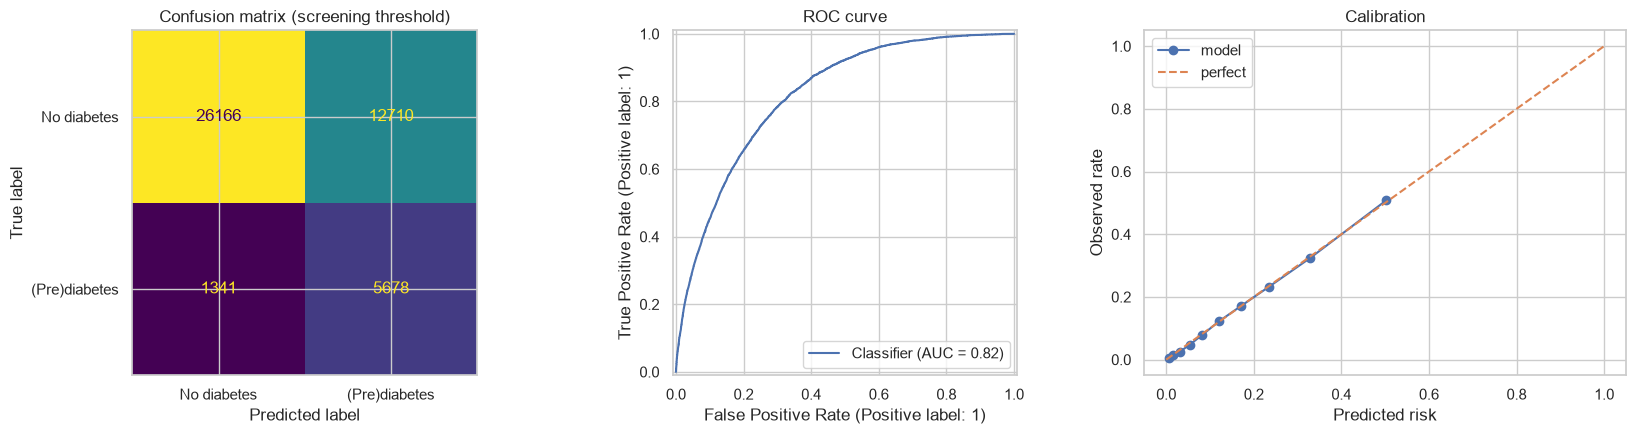

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["No diabetes", "(Pre)diabetes"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (screening threshold)")
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1]); axes[1].set_title("ROC curve")
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, "o-", label="model"); axes[2].plot([0, 1], [0, 1], "--", label="perfect")
axes[2].set_xlabel("Predicted risk"); axes[2].set_ylabel("Observed rate"); axes[2].set_title("Calibration"); axes[2].legend()
plt.tight_layout(); plt.show()

In [17]:
# Error analysis: who does the model miss (false negatives) vs. catch (true positives)?
err = X_test.assign(y=y_test.values, pred=pred_test)
fn = err[(err.y == 1) & (err.pred == 0)].drop(columns=["y", "pred"])
tp = err[(err.y == 1) & (err.pred == 1)].drop(columns=["y", "pred"])
fp = err[(err.y == 0) & (err.pred == 1)].drop(columns=["y", "pred"])
print(f"Missed (FN): {len(fn)}   Caught (TP): {len(tp)}   False alarms (FP): {len(fp)}")
pd.DataFrame({"missed (FN)": fn.mean(), "caught (TP)": tp.mean(), "false alarm (FP)": fp.mean()}).round(2)

Missed (FN): 1341   Caught (TP): 5678   False alarms (FP): 12710


,missed (FN),caught (TP),false alarm (FP)
HighBP,0.36,0.85,0.78
HighChol,0.40,0.74,0.66
CholCheck,0.97,1.00,1.00
BMI,27.82,33.08,31.10
Smoker,0.46,0.53,0.52
Stroke,0.03,0.11,0.08
HeartDiseaseorAttack,0.06,0.26,0.20
PhysActivity,0.76,0.59,0.64
Fruits,0.62,0.57,0.60
Veggies,0.80,0.74,0.76


## 8 · Short questionnaire (stretch goal)
Real users won't answer 21 questions. We rank features with permutation importance computed on a **validation split taken from the training set only**, then retrain with the top-*k* questions and see how much performance we lose.

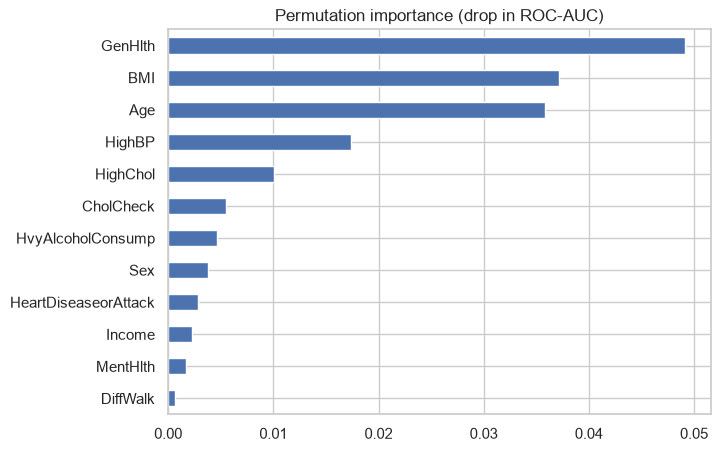

In [18]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
rank_model = make_pipeline(HistGradientBoostingClassifier(**HGB_BASE, **best_params), ALL_FEATURES).fit(X_tr, y_tr)
val_sample = X_val.sample(min(20000, len(X_val)), random_state=RANDOM_STATE)
pi = permutation_importance(rank_model, val_sample, y_val.loc[val_sample.index], scoring="roc_auc",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
importance.head(12).iloc[::-1].plot(kind="barh", figsize=(7, 5), title="Permutation importance (drop in ROC-AUC)")
plt.show()
ranking = list(importance.index)

In [19]:
rows = []
for k in [5, 7, 10, 15, len(ALL_FEATURES)]:
    feats = ranking[:k]
    mdl = make_pipeline(HistGradientBoostingClassifier(**HGB_BASE, **best_params), feats).fit(X_train[feats], y_train)
    t = pick_threshold(mdl, X_train[feats], y_train)
    mt, _, _ = evaluate(mdl, X_test[feats], y_test, t)
    rows.append({"questions": k, "threshold": round(t, 3), **{a: round(b, 3) for a, b in mt.items()}})
short_table = pd.DataFrame(rows).set_index("questions")
short_table

,threshold,ROC-AUC,PR-AUC,Recall,Precision,F1
questions,,,,,,
5,0.139,0.811,0.432,0.808,0.297,0.435
7,0.141,0.814,0.437,0.807,0.302,0.440
10,0.142,0.818,0.445,0.813,0.306,0.445
15,0.143,0.819,0.446,0.810,0.309,0.447
21,0.143,0.819,0.446,0.809,0.309,0.447


## 9 · Save the final model for the web app
We ship the **short questionnaire model** (`K_FINAL` questions). The file also stores the threshold and a "typical person without diabetes" reference profile, which the app uses to explain which answers raise the risk.

In [20]:
final_feats = ranking[:K_FINAL]
print("Final questions:", final_feats)

final_model = make_pipeline(HistGradientBoostingClassifier(**HGB_BASE, **best_params), final_feats).fit(X_train[final_feats], y_train)
thr_final = pick_threshold(final_model, X_train[final_feats], y_train)
final_metrics, _, _ = evaluate(final_model, X_test[final_feats], y_test, thr_final)
print({k: round(v, 3) for k, v in final_metrics.items()}, "threshold:", round(thr_final, 3))

reference = X_train.loc[y_train == 0, final_feats].median().to_dict()
joblib.dump({"model": final_model, "features": final_feats, "threshold": thr_final,
             "reference": reference, "metrics": final_metrics, "target_recall": TARGET_RECALL},
            "model.joblib", compress=3)
print("Saved model.joblib")

Final questions: ['GenHlth', 'BMI', 'Age', 'HighBP', 'HighChol', 'CholCheck', 'HvyAlcoholConsump']
{'ROC-AUC': 0.814, 'PR-AUC': 0.437, 'Recall': 0.807, 'Precision': 0.302, 'F1': 0.44} threshold: 0.141
Saved model.joblib


## 10 · Business insight and limitations
**What the results mean (fill in with your numbers).** At the screening threshold the short questionnaire flags about **[recall]%** of people who have (pre)diabetes, at the price of **[precision]%** precision — i.e. most flagged people are false alarms. That is acceptable for a *cheap first filter*: a flag only means "get a blood test", and a missed case costs more than an extra test.

**What the organisation should do next**
1. Use the short form as a pre-screening step at community events, pharmacies and clinics; send flagged people for an HbA1c / fasting glucose test.
2. Set the threshold from the cost of a test vs. the cost of a missed case, not from accuracy — the app's risk levels are built on this threshold.
3. Run a pilot, measure how many flagged people are truly diagnosed, and retrain on local data.

**Limitations**
- Data are **self-reported**, from **US adults in 2015**; performance in other countries (e.g. Egypt) and today is unknown and must be validated before real use.
- The label mixes diabetes and prediabetes, and several features (high blood pressure, poor health) are *consequences or companions* of diabetes, not causes → the tool shows association, not causation.
- Many false alarms at high recall; probabilities are only roughly calibrated.
- Check performance across sex, age and income groups before deployment (possible fairness gaps).
- **This is a screening aid, not a medical diagnosis.**

In [21]:
# Results summary for the README / CV bullet / LinkedIn post (all numbers come from this run)
print(cv_table.to_string(), "\n")
print(test_table.to_string(), "\n")
print(short_table.to_string(), "\n")
n_rows = len(df)
print(f"CV bullet: Built a diabetes risk-screening tool from ~{n_rows:,} CDC survey responses, "
      f"reducing the questionnaire to {K_FINAL} key questions while keeping recall {final_metrics['Recall']:.0%} "
      f"(ROC-AUC {final_metrics['ROC-AUC']:.2f}); deployed with Streamlit.")

                           CV ROC-AUC  CV PR-AUC
model                                           
Baseline (majority class)      0.5000     0.1529
Logistic Regression            0.8062     0.4056
Random Forest                  0.8121     0.4302
Hist Gradient Boosting         0.8147     0.4320 

                              ROC-AUC  PR-AUC  Recall  Precision     F1
Baseline                        0.500   0.153   0.000      0.000  0.000
Best model @0.5                 0.819   0.446   0.166      0.601  0.260
Best model @0.14 (screening)    0.819   0.446   0.809      0.309  0.447 

           threshold  ROC-AUC  PR-AUC  Recall  Precision     F1
questions                                                      
5              0.139    0.811   0.432   0.808      0.297  0.435
7              0.141    0.814   0.437   0.807      0.302  0.440
10             0.142    0.818   0.445   0.813      0.306  0.445
15             0.143    0.819   0.446   0.810      0.309  0.447
21             0.143    0.819 